# Solitons, recurrence and collisions

Fundamental solitons balance dispersion and nonlinearity. Higher-order solitons breathe. The collision study uses initially separated moving pulses and reports position changes against independent propagation.

All measurements here are synthetic. This notebook runs a small independent calculation and then inspects a retained study figure. It does not launch full training or overwrite the saved scientific results.

In [1]:

from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists() and (p / "src/optics_portfolio").exists())
%matplotlib inline

PROJECT = ROOT


## Calculate and inspect

Read the calculation before executing. Compare numerical values with the stated physical assumptions.

In [2]:
from optics_portfolio.fiber import grid,sech,propagate,relative_error
t,_=grid(1024,40)
field=propagate(sech(t),t,np.pi/2,1600,g=4,save_every=1600)[1][-1]
print("N=2 amplitude recurrence error:",relative_error(abs(field),sech(t)))
metrics=json.loads((PROJECT/"results/advanced_metrics.json").read_text())
print(json.dumps(metrics["recurrence"],indent=2))

N=2 amplitude recurrence error: 1.6184109814889776e-05
[
  {
    "N": 2,
    "refinement": [
      {
        "grid": 1024,
        "steps": 2400,
        "relative_amplitude_recurrence_error": 7.193449425339957e-06,
        "edge_energy_fraction": 4.752971716045343e-15,
        "high_frequency_energy_fraction": 2.7261470407423626e-23
      },
      {
        "grid": 2048,
        "steps": 4800,
        "relative_amplitude_recurrence_error": 1.7984407249387397e-06,
        "edge_energy_fraction": 4.94076295484764e-15,
        "high_frequency_energy_fraction": 3.384809140745198e-24
      }
    ]
  },
  {
    "N": 3,
    "refinement": [
      {
        "grid": 1024,
        "steps": 2400,
        "relative_amplitude_recurrence_error": 0.0001146017295178807,
        "edge_energy_fraction": 2.3348357788552475e-14,
        "high_frequency_energy_fraction": 2.7441620560015796e-23
      },
      {
        "grid": 2048,
        "steps": 4800,
        "relative_amplitude_recurrence_error": 2.866

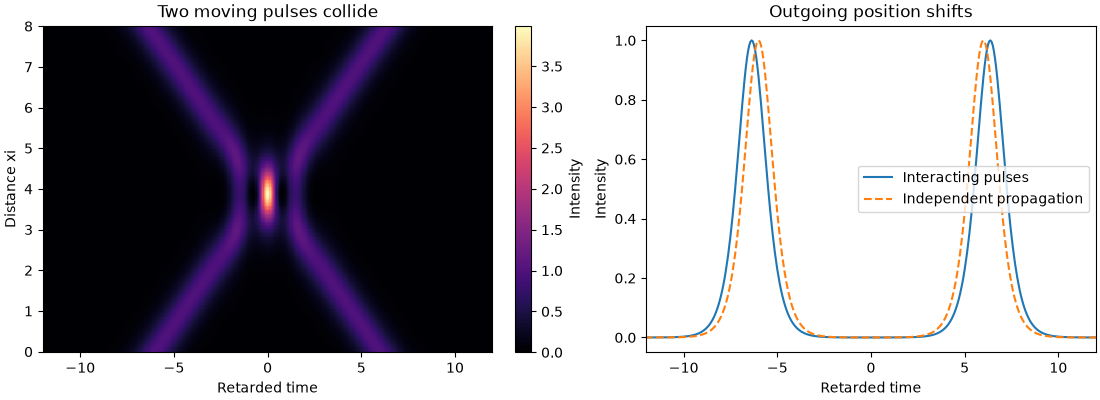

In [3]:
display(Image(filename=str(PROJECT / "results/soliton_collision.png")))

## Interpret and extend

Why is recurrence measured with amplitude rather than raw complex field? Why does a sum of two separated sech pulses not constitute an exact analytical two-soliton solution?

See `../report/technical_report.md` and the project README for the full experiment and limitations. Record your own changed settings and conclusions in a separate run.